# Step 6 on the test: backtest of `finbert_episode` (17 September - 30 October 2026)

**Question.** Does the variant chosen on the train, `finbert_episode`, improve the strategy on data that nobody had looked at? Three versions are compared: **A** enters at every signal, **B** can block the trade, **C** can also follow the news (enter in the direction opposite to A).

**Rules written beforehand.** The rules and the way of judging the result are in [docs/Test.md](../docs/Test.md), written before downloading the test data. They are the same as the train, unchanged: signal of `03_signals.ipynb`, decisions of [agent_variants/episode.py](agent_variants/episode.py), engine of [backtest.py](backtest.py). 10,000 dollars per leg, 300,000 of capital, cost **0** as the main scenario and **5** as a comparison.

**Main criterion:** the dollar difference between B and A, and between C and A, at cost 0.

**The test was done only once.** [test_final.py](test_final.py) computed signals, decisions and trades on 14 November 2026 and saved them in `Results/test/`; it is not redone. Before doing it, the same functions redid the train and found exactly its 973 signals and the decisions and trades of `finbert_episode`. This notebook only reads those files: it can be rerun without redoing the test. The robustness checks are in [Step 7 on the test](07_test_robustness.ipynb).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, next(str(p) for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()))   # project folder: makes src importable

import pandas as pd
import matplotlib.pyplot as plt

from src.config import NEWS_TEST, RESULTS, RESULTS_TEST, TEST_START, TEST_END, read_parquet
from src.backtest import load_trades, add_costs, daily_pnl, summary, by_group, breakeven_cost, entry_window, save_results
from src.signals import list_pairs, load_pair
from src.agent_variants.comparison import Variant, evaluate_blocks, evaluate_follows

pd.options.display.float_format = "{:,.2f}".format
pd.options.display.width = 220
A = load_trades(RESULTS_TEST / "trades_A.csv", allow_test=True)
B = load_trades(RESULTS_TEST / "trades_B.csv", allow_test=True)
C = load_trades(RESULTS_TEST / "trades_C.csv", allow_test=True)
dec = pd.read_csv(RESULTS_TEST / "decisions.csv", parse_dates=["t_signal", "ep_start"])
d0 = load_pair(list_pairs().pair.iloc[0])
days = pd.DatetimeIndex(d0.ts.normalize().unique())
days = days[(days >= TEST_START) & (days <= TEST_END)]   # trading days of the test, including those without trades
VERSIONS = {"A": A, "B": B, "C": C}
variants = [Variant("finbert_episode", v, "A", True, "FinBERT, episode window", t) for v, t in (("B", B), ("C", C))]
ref = {"A": A}
print(f"{len(A)} signals in {len(days)} days ({days.min():%d/%m} - {days.max():%d/%m}), {len(read_parquet(NEWS_TEST))} news; "
      f"{(dec.decision == 'block').sum()} blocks in B, {(dec.decision_C == 'follow').sum()} follows in C")

500 signals in 32 days (17/09 - 30/10), 1729 news; 7 blocks in B, 24 follows in C


## 1. Version A on the test

The reference. Profit per cost, per pair, per entry time and per exit reason, next to the same numbers of the train.

In [2]:
def per_cost(t, costs=(0, 5)):
    rows = {c: summary(add_costs(t, c), days) for c in costs}
    return pd.DataFrame(rows).T.rename_axis("cost_bps")

A_train = pd.read_csv(RESULTS / "A_by_cost.csv", index_col=0).loc[[0, 5]]
cols = ["trade", "gross_bps", "net_bps", "se_bps", "win_rate", "profit_factor", "pnl_usd", "total_return", "sharpe", "max_drawdown"]
tab = pd.concat({"test": per_cost(A)[cols], "train": A_train[cols]}, names=["period", "cost_bps"])
tab.assign(total_return=100 * tab.total_return, max_drawdown=100 * tab.max_drawdown).rename(columns={"total_return": "total_return_pct", "max_drawdown": "max_drawdown_pct"})

trade  gross_bps  net_bps  se_bps  win_rate  profit_factor    pnl_usd  total_return_pct  sharpe  max_drawdown_pct
period cost_bps                                                                                                                   
test   0        500.00       4.94     4.94    2.36      0.63           1.31   2,472.42              0.82    4.92             -0.17
       5        500.00       4.94   -15.06    2.36      0.36           0.41  -7,527.58             -2.51  -15.30             -2.65
train  0        973.00       7.44     7.44    2.03      0.60           1.45   7,239.43              2.41    8.13             -0.15
       5        973.00       7.44   -12.56    2.03      0.39           0.52 -12,220.57             -4.07  -13.55             -4.07

In [3]:
print(f"Break-even cost on the test: {breakeven_cost(A):.2f} basis points per operation (train 1.86)")
A_train_pair = pd.read_csv(RESULTS / "A_by_pair.csv", index_col=0)
pp = by_group(A, "pair", cost_bps=0)[["trade", "gross_bps", "se_bps", "win_rate"]]
pp.join(A_train_pair[["trade", "gross_bps"]].add_suffix("_train")).sort_values("gross_bps", ascending=False)

Break-even cost on the test: 1.24 basis points per operation (train 1.86)


,trade,gross_bps,se_bps,win_rate,trade_train,gross_bps_train
pair,,,,,,
ISRG-SYK,26,25.74,16.54,0.73,63,-3.20
CRM-WDAY,30,15.79,14.38,0.63,60,28.19
CL-PG,28,12.75,6.39,0.71,63,6.61
MA-V,43,9.39,2.43,0.70,75,7.54
HD-LOW,38,9.14,4.17,0.68,65,4.39
CSX-UNP,32,7.31,4.62,0.69,61,6.81
DHR-TMO,35,6.20,7.67,0.71,62,6.59
JPM-WFC,41,4.09,4.23,0.61,65,4.31
KO-PEP,33,4.05,6.88,0.61,68,3.53


In [4]:
display(by_group(A, entry_window(A), cost_bps=0)[["trade", "gross_bps", "se_bps", "win_rate"]])
by_group(A, "exit_reason", cost_bps=0)[["trade", "gross_bps", "se_bps", "win_rate"]]

,trade,gross_bps,se_bps,win_rate
window,,,,
after 30 min,271,5.02,2.35,0.63
open (15-30 min),229,4.86,4.35,0.63


,trade,gross_bps,se_bps,win_rate
exit_reason,,,,
end_of_day,22,-9.12,6.94,0.41
reversion,244,32.96,1.58,0.97
stop,7,-4.02,11.82,0.43
time,227,-23.53,4.04,0.30


## 2. The main criterion: B and C against A

Metrics of A, B and C on the test at cost 0 (main) and 5 (comparison), and the dollar difference from A (`delta_pnl_usd`). The Sharpe ratio is computed on 32 days and scaled to a year: it is not very reliable and must not be compared with that of a fund.

In [5]:
rows = []
for c in (0, 5):
    r = summary(add_costs(A, c), days)
    for v, t in VERSIONS.items():
        s = summary(add_costs(t, c), days)
        rows.append(dict(version=v, cost_bps=c, trade=s["trade"], net_bps=s["net_bps"], win_rate=s["win_rate"], profit_factor=s["profit_factor"],
                         pnl_usd=s["pnl_usd"], delta_pnl_usd=s["pnl_usd"] - r["pnl_usd"], sharpe=s["sharpe"], max_drawdown_pct=100 * s["max_drawdown"]))
test_comparison = pd.DataFrame(rows).set_index(["cost_bps", "version"])
test_comparison

trade  net_bps  win_rate  profit_factor   pnl_usd  delta_pnl_usd  sharpe  max_drawdown_pct
cost_bps version                                                                                            
0        A          500     4.94      0.63           1.31  2,472.42           0.00    4.92             -0.17
         B          493     4.63      0.63           1.29  2,283.56        -188.86    4.73             -0.19
         C          495     2.48      0.61           1.15  1,229.96      -1,242.46    2.77             -0.21
5        A          500   -15.06      0.36           0.41 -7,527.58           0.00  -15.30             -2.65
         B          493   -15.37      0.35           0.40 -7,576.44         -48.86  -15.91             -2.65
         C          495   -17.52      0.34           0.35 -8,670.04      -1,142.46  -19.85             -3.00

**Rule for the zero cases** (written beforehand): if the agent blocks no trade, B coincides with A and the test says nothing about the blocks; the same for C if it follows no news.

In [6]:
n_blocks, n_follows = int((dec.decision == "block").sum()), int((dec.decision_C == "follow").sum())
n_inverted = int((C.c_kind == "follow").sum())
print(f"B: {n_blocks} trades blocked of {len(A)}" + (" -> B coincides with A: the test says nothing about the blocks" if n_blocks == 0 else ""))
print(f"C: {n_follows} follows, of which {n_inverted} in the direction opposite to A and {n_follows - n_inverted} in the same direction (they stay the A trade)"
      + (" -> C coincides with B: the test says nothing about following" if n_inverted == 0 else ""))

B: 7 trades blocked of 500
C: 24 follows, of which 21 in the direction opposite to A and 3 in the same direction (they stay the A trade)


## 3. Does the agent choose well?

The same checks as the train (Step 6, section 4), next to the train values.

- **B**: do the blocked trades revert less than the kept ones (`p_fisher`, Fisher's exact test)? Are they worse than 5,000 random blocks of the same number (`p_random`: below 0.05 the agent removes worse trades than chance, close to 1 it removes precisely the best ones)?
- **C**: when the agent enters in the direction opposite to A, was the news right? `news_right` is the share of those trades in profit.

In [7]:
blocks = pd.concat({"test": evaluate_blocks(variants, ref).loc[["finbert_episode"]],
                    "train": pd.read_csv(RESULTS / "blocked_vs_random.csv", index_col=0).loc[["finbert_episode"]]}, names=["period"])
blocks

,,reference,blocked,reversion_blocked,reversion_kept,p_fisher,gross_mean_blocked,gross_median_blocked,gross_mean_kept,p_random
period,variant,,,,,,,,,
test,finbert_episode,A,7,0.43,0.49,1.00,26.98,37.48,4.63,0.90
train,finbert_episode,A,5,0.00,0.48,0.06,56.98,-8.97,7.18,0.97


In [8]:
follows = pd.concat({"test": evaluate_follows(variants, ref).loc[["finbert_episode"]],
                     "train": pd.read_csv(RESULTS / "news_right_C.csv", index_col=0).loc[["finbert_episode"]]}, names=["period"])
follows

,,reference,follow,news_right,gross_mean_C,gross_median_C,gross_mean_ref_same
period,variant,,,,,,
test,finbert_episode,A,21,0.24,-25.05,-23.09,25.05
train,finbert_episode,A,20,0.55,-8.92,5.82,8.92


**The blocked trades, one by one**, with the targeted news that the agent read in the episode and the result they would have had in A.

In [9]:
pd.options.display.max_colwidth = 160
blk = dec[dec.decision == "block"].merge(A[["signal_id", "exit_reason", "gross_bps"]], on="signal_id")
blk[["signal_id", "pair", "t_signal", "ep_kind", "n_strong", "exit_reason", "gross_bps", "headlines"]]

,signal_id,pair,t_signal,ep_kind,n_strong,exit_reason,gross_bps,headlines
0,80,ISRG-SYK,2026-09-25 09:45:00,overnight,1,reversion,37.48,"Here's How Much $1000 Invested In Intuitive Surgical 10 Years Ago Would Be Worth Today | Bronstein, Gewirtz & Grossman, LLC Investigates Potential Claims Ag..."
1,111,ISRG-SYK,2026-09-29 09:45:00,overnight,1,time,54.09,Pomerantz LLP Announces Investigation into Stryker Corporation
2,127,DHR-TMO,2026-09-29 15:09:00,in session,1,end_of_day,25.25,Leica Biosystems Completes Acquisition of StatLab Medical Products
3,193,BAC-C,2026-10-06 09:45:00,in session,1,reversion,63.13,Capitolis Secures $220 Million in Financing with Participation from Citi | Bank of America Launches Expanded Fraud-Awareness Initiative for Small Businesses
4,353,CRM-WDAY,2026-10-20 09:50:00,overnight,1,time,-95.21,Salesforce Launches Slack Frontline Add-on for Enterprise+ Customers | Salesforce To Acquire Braze For ~$5.66B | Salesforce Bets $5.7 Billion on AI Marketin...
5,418,ISRG-SYK,2026-10-26 09:45:00,in session,1,time,10.48,Stryker Completes Acquisition of ZuriMED
6,487,CRM-WDAY,2026-10-30 09:45:00,overnight,1,reversion,93.65,Salesforce to Acquire Defense Tech Firm Rune Technologies


**The trades followed in the direction opposite to A**: profit of C and the profit A would have had on the same signal.

In [10]:
f = C[C.c_kind == "follow"].merge(A[["signal_id", "gross_bps"]], on="signal_id", suffixes=("_C", "_A"))
f = f.merge(dec[["signal_id", "ep_kind", "rel_score"]], on="signal_id")
f[["signal_id", "pair", "t_signal", "ep_kind", "rel_score", "direction", "exit_reason", "gross_bps_C", "gross_bps_A"]]

,signal_id,pair,t_signal,ep_kind,rel_score,direction,exit_reason,gross_bps_C,gross_bps_A
0,15,KO-PEP,2026-09-18 09:45:00,overnight,0.86,long KO / short PEP,time,-15.67,15.67
1,16,PYPL-XYZ,2026-09-18 09:45:00,overnight,-0.93,short PYPL / long XYZ,reversion,-48.31,48.31
2,13,GS-MS,2026-09-18 09:45:00,overnight,-1.03,short GS / long MS,time,34.56,-34.56
3,12,DHR-TMO,2026-09-18 09:45:00,overnight,-0.74,short DHR / long TMO,time,-36.07,36.07
4,26,JPM-WFC,2026-09-21 09:45:00,overnight,1.28,long JPM / short WFC,time,-31.64,31.64
5,28,MA-V,2026-09-21 09:46:00,overnight,0.61,long MA / short V,reversion,-10.33,10.33
6,48,CRM-WDAY,2026-09-23 09:45:00,overnight,0.88,long CRM / short WDAY,reversion,-129.97,129.97
7,51,PYPL-XYZ,2026-09-23 09:45:00,overnight,0.79,long PYPL / short XYZ,time,-21.97,21.97
8,194,COP-EOG,2026-10-06 09:45:00,overnight,0.91,long COP / short EOG,time,21.03,-21.03
9,219,JPM-WFC,2026-10-07 11:04:00,in session,0.86,long JPM / short WFC,time,45.13,-45.13


## 4. Consistency with the train

Does the difference from A, at cost 0, have the same sign as on the train? The differences are also expressed per trading day, because the test has half the days of the train.

In [11]:
train_cmp = pd.read_csv(RESULTS / "version_comparison.csv").query("variant == 'finbert_episode'").set_index(["cost_bps", "version"])
cons = pd.DataFrame({
    "delta_train_usd": train_cmp.delta_pnl_usd,
    "delta_test_usd": test_comparison.query("version != 'A'").delta_pnl_usd,
})
cons["delta_train_per_day"] = cons.delta_train_usd / 64
cons["delta_test_per_day"] = cons.delta_test_usd / len(days)
cons["same_sign"] = (cons.delta_train_usd > 0) == (cons.delta_test_usd > 0)
cons

delta_train_usd  delta_test_usd  delta_train_per_day  delta_test_per_day  same_sign
cost_bps version                                                                                     
0        B                -284.92         -188.86                -4.45               -5.90       True
         C                -650.77       -1,242.46               -10.17              -38.83       True
5        B                -184.92          -48.86                -2.89               -1.53       True
         C                -570.77       -1,142.46                -8.92              -35.70       True

## 5. Equity curves (cost 0)

Cumulative return on the capital of 300,000 dollars, day by day, for A, B and C on the test.

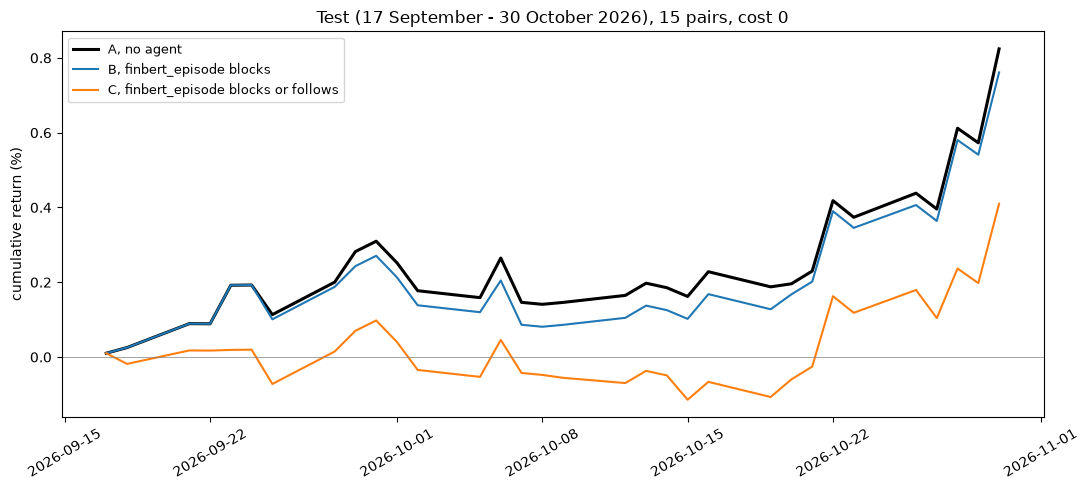

In [12]:
eq = lambda t: daily_pnl(add_costs(t, 0), days).equity * 100   # noqa: E731
fig, ax = plt.subplots(figsize=(11, 5))
for (v, t), color, lw in zip(VERSIONS.items(), ("black", "tab:blue", "tab:orange"), (2.2, 1.5, 1.5)):
    ax.plot(days, eq(t), color=color, lw=lw, label={"A": "A, no agent", "B": "B, finbert_episode blocks", "C": "C, finbert_episode blocks or follows"}[v])
ax.axhline(0, color="grey", lw=0.5)
ax.set_ylabel("cumulative return (%)")
ax.set_title("Test (17 September - 30 October 2026), 15 pairs, cost 0")
ax.tick_params(axis="x", rotation=30)
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(RESULTS_TEST / "equity_curves.png", dpi=120)
plt.show()

## 6. Saving

Tables in `Results/test/`, on git.

In [13]:
tables = {"test/version_comparison": test_comparison, "test/A_by_cost": per_cost(A), "test/A_by_pair": by_group(A, "pair", cost_bps=0),
          "test/blocked_vs_random": blocks, "test/news_right_C": follows, "test/consistency_with_train": cons}
for p in save_results(tables):
    print(p.relative_to(RESULTS.parent))

Results/test/version_comparison.csv
Results/test/A_by_cost.csv
Results/test/A_by_pair.csv
Results/test/blocked_vs_random.csv
Results/test/news_right_C.csv
Results/test/consistency_with_train.csv


## 7. What the results tell us

Numbers from the tables above: test, from 17 September to 30 October 2026, 15 pairs, 500 signals, cost 0 unless stated.

**Version A.** 500 trades with +4.94 gross basis points each (train 7.44): +2,472 dollars on 300,000 in 32 days (+0.8%). The base strategy still earns at cost 0, but less than on the train. Break-even drops to 1.24 bps per operation (train 1.86): at 5 bps A loses 7,528 dollars.
- The trades that revert earn (244 trades, +33 bps); those closed after 90 minutes lose (227 trades, -23.5 bps).
- On the test the overnight gap no longer makes the difference: 4.9 bps for the entries in minutes 15-30 and 5.0 after (train 11.4 against 3.9).
- The pairs change a lot. PYPL-XYZ, the best of the train (+29.6 bps), is at -3.4 on the test; ISRG-SYK goes from -3.2 to +25.7. The standard errors per pair are large.

**Main criterion (cost 0).** B earns **189 dollars less than A**, C **1,242 dollars less**. As on the train (B -285, C -651), neither of the two beats A. At cost 5: B -49, C -1,142.

**B: does the agent block the right trades?** No. Out of 500 signals it blocks 7. In A those trades would have earned on average +27 bps (median +37), against +4.6 for the kept trades. They revert in 43% of the cases against 49% for the kept ones (p Fisher 1.00). The check with random blocks gives p = 0.90: the agent removes trades better than the average, as on the train (p = 0.97).

The news of the blocks explain why. The keyword rule fires on news that are not structural facts pushing the two prices apart:
- two blocks on ISRG-SYK come from press releases of law firms that "investigate" possible class actions;
- three come from acquisitions made by the company of the pair: Stryker buys ZuriMED, Salesforce buys Braze and Rune Technologies;
- one from an acquisition by Leica Biosystems (Danaher group), one from a Bank of America initiative against fraud.

The rules are not changed after the test: it is a limit to be stated.

**C: does following the news make sense?** No. In 21 signals C enters in the direction opposite to A: the news is right only in **24%** of the cases (train 55%). Those trades lose on average 25 bps, while A on the same signals would have earned 25 bps. In 15 of the 21 the episode started overnight.

**Consistency with the train.** In all four comparisons (B and C, cost 0 and 5) the difference from A has the same sign as on the train: negative. Per trading day B loses about as much as on the train (5.9 dollars a day against 4.5), C much more (38.8 against 10.2).

**In short.** On the test `finbert_episode` does not improve the strategy: B loses 189 dollars relative to A, C 1,242. The result confirms that of the train. The best version is still A, without the agent, which however earns less than on the train and loses with realistic costs. Whether the differences are real or luck is told by [Step 7 on the test](07_test_robustness.ipynb).

**Limits.**
- 32 days, 7 blocks and 21 followed trades: few cases, every number has a lot of uncertainty.
- The test has many more news per day than the train: 2,725 in 44 calendar days, against 2,106 in 108. The October earnings season probably weighs.
- Signal, variant and thresholds were chosen on the train; the test was used only once.
- The rules in [docs/Test.md](../docs/Test.md) were written before the run but committed to git afterwards: git holds no proof that they come before the test. It must be stated in the report.